# Phase-4C — TrustFin-SLM Ablations, Statistical Evaluation and Methodology Freeze

**Why this phase?** Phase-4A established that deterministic execution beats copying the SLM's written answer, but validity and number-presence do not prove correct financial reasoning. Phase-4B fits a risk estimator on calibration-fit examples, freezing model/threshold selection before evaluating on a held-out subset of the Phase-2.1 validation data. Phase-4C asks: **Does the full system actually improve *selective reliability* over execution-only and simple likelihood selection?**

**Study limitations:** Phase-4C is a **validation-level study** on the same 185/25 calibration holdouts already summarized by Phase-4B; it does not create a second independent test set. Do not change features or thresholds after viewing holdout outcomes. Protected FinQA/FiQA tests and FinTrust dimensions are not accessed here.

| Experiment | Analysis |
|---|---|
| C1 | Frozen E5 generated-answer baseline |
| C2 | Execution-only corrected-answer baseline |
| C3 | Hard program/evidence-grounding checks |
| C4 | Likelihood-only abstention (B1/B2) |
| C5 | Frozen verifier-aware abstention (B3/B4 and fit-only winner) |
| C6 | Full TrustFin-SLM selective answering policy |
| C7 | Grounding/verification/calibration component ablations |
| C8 | Paired significance, bootstrap CIs, coverage-standardized comparisons |
| C9 | Efficiency and honest offline-overhead reporting |
| C10 | Methodology freeze and paper-ready exports |

## How to run

1. Complete Phase-4B in **full mode** and confirm `phase4b_readiness.json` = `PASS_FROZEN`. Never run Phase-4C with a smoke-stage B freeze.
2. Keep `Phase4A_Review_Package(1).zip` and **Phase-3 deliverable ZIP** available for original predictions and latency metadata. No GPU or training required.
3. Place this notebook next to Phase-4B's notebook. By default it reads `artifacts/phase4b_full/` and auto-locates the two ZIPs. Otherwise set `TRUSTFIN_PHASE4B_ROOT`, `TRUSTFIN_PHASE4A_ZIP`, `TRUSTFIN_PHASE3_ZIP`, and optionally `TRUSTFIN_WORKSPACE`.
4. Run **Kernel → Restart & Run All**. The C1–C10 analyses use only fixed Phase-4B holdout scores and the original E5 saved predictions; all thresholds are imported from fit-only Phase-4B metadata.
5. Review the final `phase4c_readiness.json`. A methodological **PASS** does not prove the proposed method is better; report actual effects and CIs even when null or unfavorable.
6. Share the **executed notebook**, `Phase4C_Review_Package.zip`, `phase4c_readiness.json`, `phase4_methodology_freeze.json`, and core C1–C9 CSV reports. Preserve E5/Phase-4B models locally.

**Avoid:** using validation holdout labels to change the chosen risk estimator, setting new thresholds on holdout, or describing validation-only effects as test-set results.

In [1]:
import os, json, hashlib, zipfile, io, platform, time
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import binomtest
from sklearn.metrics import roc_auc_score
SEED=42
WORKSPACE_ROOT=Path(os.environ.get('TRUSTFIN_WORKSPACE',str(Path.cwd()))).expanduser().resolve()
B_ROOT=Path(os.environ.get('TRUSTFIN_PHASE4B_ROOT',str(WORKSPACE_ROOT/'artifacts/phase4b_full')))
OUT=WORKSPACE_ROOT/'artifacts/phase4c_full'
for sub in ['tables','plots','manifests','predictions']:(OUT/sub).mkdir(parents=True,exist_ok=True)
assert (B_ROOT/'manifests/phase4b_readiness.json').is_file(),f'Phase-4B full output missing: {B_ROOT}'
def load(path):return json.loads(Path(path).read_text(encoding='utf-8'))
def save(name,obj):
    p=OUT/'manifests'/name
    p.write_text(json.dumps(obj,indent=2,default=str),encoding='utf-8');return p
B_READY=load(B_ROOT/'manifests/phase4b_readiness.json')
B_FREEZE=load(B_ROOT/'manifests/phase4b_freeze.json')
assert B_READY['status']=='PASS_FROZEN' and B_FREEZE['status']=='PASS_FROZEN'
print('Loaded frozen Phase-4B winner:',B_FREEZE['winner_from_fit_oof'])

Loaded frozen Phase-4B winner: B1_raw


In [2]:
import os, shutil
from pathlib import Path

# Force correct paths (running from notebooks/ breaks relative lookups)
os.environ["TRUSTFIN_WORKSPACE"] = "/home/heet18/Downloads/Research Papers"
os.environ["TRUSTFIN_PHASE4B_ROOT"] = "/home/heet18/Downloads/Research Papers/artifacts/phase4b_full"
os.environ["TRUSTFIN_PHASE4A_ZIP"] = "/home/heet18/Downloads/Research Papers/artifacts/phase4a/Phase4A_Review_Package.zip"
os.environ["TRUSTFIN_PHASE3_ZIP"] = "/home/heet18/Downloads/Research Papers/deliverables/Phase3_TrustFin_Deliverable.zip"

# Rebind to repo root
WORKSPACE_ROOT = Path(os.environ["TRUSTFIN_WORKSPACE"]).resolve()
B_ROOT = Path(os.environ["TRUSTFIN_PHASE4B_ROOT"]).resolve()

# Fallback: copy zips to current working dir (notebooks/) in case locate_zip only checks cwd
cwd = Path.cwd()
for src in [
    Path("/home/heet18/Downloads/Research Papers/artifacts/phase4a/Phase4A_Review_Package.zip"),
    Path("/home/heet18/Downloads/Research Papers/deliverables/Phase3_TrustFin_Deliverable.zip"),
]:
    dst = cwd / src.name
    if src.exists() and not dst.exists():
        shutil.copy(src, dst)
        print("Copied", src.name, "->", dst)

print("WORKSPACE_ROOT:", WORKSPACE_ROOT)
print("CWD:", cwd)
print("Phase4A ZIP:", os.environ["TRUSTFIN_PHASE4A_ZIP"])

WORKSPACE_ROOT: /home/heet18/Downloads/Research Papers
CWD: /home/heet18/Downloads/Research Papers/notebooks
Phase4A ZIP: /home/heet18/Downloads/Research Papers/artifacts/phase4a/Phase4A_Review_Package.zip


## 1. Read Phase-4A/Phase-3 inputs and check record alignment

In [3]:
def locate_zip(env,variants):
    q=os.environ.get(env,'')
    if q and Path(q).is_file():return Path(q)
    for name in variants:
        for root in [WORKSPACE_ROOT,Path.cwd(),Path('/mnt/data')]:
            p=root/name
            if p.is_file():return p
    raise FileNotFoundError(f'Set {env}: expected one of {variants}')
A_ZIP=locate_zip('TRUSTFIN_PHASE4A_ZIP',['Phase4A_Review_Package(1).zip','Phase4A_Review_Package.zip'])
if B_FREEZE.get('source_sha256'):
    assert hashlib.sha256(A_ZIP.read_bytes()).hexdigest()==B_FREEZE['source_sha256'], 'Phase-4A ZIP differs from the Phase-4B frozen source' 
P3_ZIP=locate_zip('TRUSTFIN_PHASE3_ZIP',['Phase3_TrustFin_Deliverable.zip'])
def read_zip_bytes(zp,suffix):
    with zipfile.ZipFile(zp) as z:
        found=[n for n in z.namelist() if n==suffix or n.endswith('/'+suffix)]
        if len(found)!=1:raise ValueError((zp,suffix,found))
        return z.read(found[0])
def zip_csv(zp,suffix):return pd.read_csv(io.BytesIO(read_zip_bytes(zp,suffix)))
def zip_jsonl(zp,suffix):
    return pd.DataFrame([json.loads(x) for x in read_zip_bytes(zp,suffix).decode().splitlines() if x.strip()])
E5=zip_csv(P3_ZIP,'predictions/E5.csv')
F=zip_jsonl(A_ZIP,'phase4b_interface/phase4b_finqa_features.jsonl')
FL=zip_jsonl(A_ZIP,'labels/phase4b_finqa_labels.jsonl')
Q=zip_jsonl(A_ZIP,'phase4b_interface/phase4b_fiqa_features.jsonl')
QL=zip_jsonl(A_ZIP,'labels/phase4b_fiqa_labels.jsonl')
Bscores=pd.read_csv(B_ROOT/'predictions/B1_B4_finqa_holdout_scores.csv')
Bfiqa=pd.read_csv(B_ROOT/'predictions/B6_fiqa_holdout_scores.csv')
fitmeta=load(B_ROOT/'manifests/B8_fit_only_selection.json')
assert fitmeta['holdout_not_used_for_selection']
assert E5.record_id.is_unique and len(E5)==1000
assert FL.record_id.is_unique and F.record_id.is_unique
assert set(FL.record_id)==set(F.record_id)
assert set(QL.record_id)==set(Q.record_id)
Fin=F.merge(FL,on=['record_id','calibration_fold'],validate='one_to_one')
Fin=Fin.merge(E5[E5.dataset=='FinQA'][['record_id','answer_correct','execution_correct','program_executable','latency_seconds']],
              on='record_id',validate='one_to_one',suffixes=('','_phase3'))
assert len(Fin)==883
Hold=Fin[Fin.calibration_fold=='calibration_holdout'].copy()
assert len(Hold)==185
Fi=Q.merge(QL,on=['record_id','calibration_fold'],validate='one_to_one')
assert len(Fi)==117 and len(Fi[Fi.calibration_fold=='calibration_holdout'])==25
assert set(Bscores.record_id)==set(Hold.record_id)
assert Bscores.groupby('method').record_id.nunique().eq(185).all()
print('Aligned E5 all 1000; FinQA holdout 185; FiQA holdout 25.')

Aligned E5 all 1000; FinQA holdout 185; FiQA holdout 25.


## 2. C1/C2 — Raw text answer versus deterministic executed answer

In [4]:
def boolcol(s):return s.replace({'True':True,'False':False}).fillna(False).astype(bool)
# Phase4A independently generated gold correctness labels; results are validation-only.
raw=boolcol(Fin.written_correct); executed=boolcol(Fin.execution_correct)
cont=pd.crosstab(raw,executed)
all_raw=raw.mean();all_exec=executed.mean()
C12=pd.DataFrame([
    {'method':'C1_written','n':len(Fin),'accuracy':float(all_raw),'error_rate':1-float(all_raw)},
    {'method':'C2_executed','n':len(Fin),'accuracy':float(all_exec),'error_rate':1-float(all_exec)},
    {'method':'C1_written_holdout','n':len(Hold),'accuracy':float(boolcol(Hold.written_correct).mean())},
    {'method':'C2_executed_holdout','n':len(Hold),'accuracy':float(boolcol(Hold.execution_correct).mean())},
])
C12.to_csv(OUT/'tables/C1_C2_answer_reconciliation.csv',index=False)
display(C12);display(cont)

,method,n,accuracy,error_rate
0,C1_written,883,0.375991,0.624009
1,C2_executed,883,0.674972,0.325028
2,C1_written_holdout,185,0.345946,NaN
3,C2_executed_holdout,185,0.648649,NaN


execution_correct,False,True
written_correct,,
False,286,265
True,1,331


## 3. C3–C6 — Apply **frozen** risk thresholds, no holdout selection

In [5]:
FIN_METHODS=list(fitmeta['thresholds_from_fit_oof'])
win=B_FREEZE['winner_from_fit_oof'];goal=float(fitmeta['target_coverage'])
hs=Hold.set_index('record_id');htruth=hs.execution_correct.astype(int).to_numpy()
validity=(hs.official_executable_feature.astype(bool)&hs.program_structural_valid.astype(bool))
grounding=~hs.any_literal_unmatched.astype(bool)
report=[]; decisions=[]
def record_method(name,mask,truth=htruth,group='FinQA'):
    mask=np.asarray(mask,dtype=bool)
    acc=float(np.mean(truth[mask])) if mask.any() else float('nan')
    report.append({'method':name,'dataset':group,'n':len(truth),'accepted':int(mask.sum()),
                   'coverage':float(mask.mean()),'selective_accuracy':acc,
                   'selective_risk':1-acc if np.isfinite(acc) else float('nan'),
                   'selection_note':'Phase-4B fit-only threshold; Phase-4C holdout evaluated once'})
    decisions.extend({'record_id':rid,'method':name,'accepted':bool(a)} for rid,a in zip(hs.index,mask))
record_method('C2_execution_only',np.ones(len(hs),dtype=bool))
record_method('C3_structural_gate',validity.to_numpy())
record_method('C3_grounding_gate',(validity&grounding).to_numpy())
for name in FIN_METHODS:
    subset=Bscores[Bscores.method==name].set_index('record_id').loc[hs.index]
    cut=float(fitmeta['thresholds_from_fit_oof'][name]);select=subset.p_correct.to_numpy(dtype=float)>=cut
    record_method('C4_likelihood_'+name, select&validity.to_numpy()) if name in ['B1_raw','B2_likelihood'] else None
    record_method('C5_verifier_'+name, select&validity.to_numpy()) if name in ['B3_verifier','B4_grounding'] else None
    if name==win:
        record_method('C6_full_frozen',select&validity.to_numpy())
C6=pd.DataFrame(report);C6.to_csv(OUT/'tables/C3_C6_ablation_holdout.csv',index=False)
pd.DataFrame(decisions).to_csv(OUT/'predictions/C3_C6_acceptance_masks.csv',index=False)
display(C6)

,method,dataset,n,accepted,coverage,selective_accuracy,selective_risk,selection_note
0,C2_execution_only,FinQA,185,185,1.000000,0.648649,0.351351,Phase-4B fit-only threshold; Phase-4C holdout ...
1,C3_structural_gate,FinQA,185,184,0.994595,0.652174,0.347826,Phase-4B fit-only threshold; Phase-4C holdout ...
2,C3_grounding_gate,FinQA,185,179,0.967568,0.664804,0.335196,Phase-4B fit-only threshold; Phase-4C holdout ...
3,C4_likelihood_B1_raw,FinQA,185,151,0.816216,0.649007,0.350993,Phase-4B fit-only threshold; Phase-4C holdout ...
4,C6_full_frozen,FinQA,185,151,0.816216,0.649007,0.350993,Phase-4B fit-only threshold; Phase-4C holdout ...
5,C4_likelihood_B2_likelihood,FinQA,185,151,0.816216,0.649007,0.350993,Phase-4B fit-only threshold; Phase-4C holdout ...
6,C5_verifier_B3_verifier,FinQA,185,144,0.778378,0.666667,0.333333,Phase-4B fit-only threshold; Phase-4C holdout ...
7,C5_verifier_B4_grounding,FinQA,185,147,0.794595,0.673469,0.326531,Phase-4B fit-only threshold; Phase-4C holdout ...


## 4. C7 — Component ablations and error attribution

In [6]:
details=[]
for name in ['B1_raw','B2_likelihood','B3_verifier','B4_grounding']:
    row=C6[C6.method.str.endswith(name)]
    if len(row):
        r=row.iloc[0]; details.append({'risk_model':name,'coverage':r.coverage,
            'selective_risk':r.selective_risk,'difference_from_execution_only':r.selective_risk - (1-htruth.mean())})
C7=pd.DataFrame(details);C7.to_csv(OUT/'tables/C7_component_ablation.csv',index=False)
display(C7)
# Literal mismatch subgroup is NOT a proof of semantic grounding.
subgroup=Hold.groupby('any_literal_unmatched')['execution_correct'].agg(['size','sum','mean'])
subgroup.to_csv(OUT/'tables/C7_grounding_error_subgroups.csv')
display(subgroup)

,risk_model,coverage,selective_risk,difference_from_execution_only
0,B1_raw,0.816216,0.350993,-0.000358
1,B2_likelihood,0.816216,0.350993,-0.000358
2,B3_verifier,0.778378,0.333333,-0.018018
3,B4_grounding,0.794595,0.326531,-0.024821


,size,sum,mean
any_literal_unmatched,,,
0,180,119,0.661111
1,5,1,0.200000


## 5. C8 — Paired significance and bootstrap confidence intervals

In [7]:
def paired_boot_diff(y1,y2,iterations=3000,seed=SEED):
    y1=np.asarray(y1,float); y2=np.asarray(y2,float)
    r=np.random.default_rng(seed);n=len(y1)
    diffs=np.empty(iterations)
    for t in range(iterations):
        i=r.integers(0,n,n)
        diffs[t]=y2[i].mean()-y1[i].mean()
    return [float(np.percentile(diffs,q)) for q in [2.5,97.5]]
r0=boolcol(Fin.written_correct).astype(int).to_numpy()
r1=boolcol(Fin.execution_correct).astype(int).to_numpy()
discord01=int(((r0==0)&(r1==1)).sum())
discord10=int(((r0==1)&(r1==0)).sum())
pval=float(binomtest(min(discord01,discord10),discord01+discord10,0.5).pvalue)
ci=paired_boot_diff(r0,r1)
C8A=pd.DataFrame([{'comparison':'C2_execution versus C1_written','n':len(Fin),
    'absolute_accuracy_difference':float(r1.mean()-r0.mean()),
    'bootstrap_95ci_low':ci[0],'bootstrap_95ci_high':ci[1],
    'discordant_written_wrong_execution_right':discord01,
    'discordant_written_right_execution_wrong':discord10,
    'exact_mcnemar_p':pval}])
C8A.to_csv(OUT/'tables/C8_paired_significance.csv',index=False)
display(C8A)
# Coverage-matched ranking evaluation: identical count, different accepted subsets.
Bm=Bscores.copy()
fixed_k=max(1,int(round(goal*len(hs))))
comp=[]
pmap={name:g.set_index('record_id').loc[hs.index].p_correct.to_numpy(dtype=float)
      for name,g in Bm.groupby('method')}
# For comparison, rank all cases, but invalid cases must go to the bottom.
v=validity.to_numpy(dtype=bool)
for name,p in pmap.items():
    effective=p.copy();effective[~v]=-np.inf
    order=np.argsort(-effective,kind='stable')
    acc=float(htruth[order[:fixed_k]].mean())
    comp.append({'method':name,'n':len(hs),'accepted':fixed_k,'coverage':fixed_k/len(hs),
                 'matched_count_selective_risk':1-acc,
                 'warning':'If all valid < target k, some invalid enter rank tail; see valid count.'})
C8B=pd.DataFrame(comp).sort_values('matched_count_selective_risk')
C8B.to_csv(OUT/'tables/C8_coverage_matched_comparison.csv',index=False)
display(C8B)

,comparison,n,absolute_accuracy_difference,bootstrap_95ci_low,bootstrap_95ci_high,discordant_written_wrong_execution_right,discordant_written_right_execution_wrong,exact_mcnemar_p
0,C2_execution versus C1_written,883,0.298981,0.269536,0.329558,265,1,4.503627e-78


,method,n,accepted,coverage,matched_count_selective_risk,warning
3,B4_grounding,185,148,0.8,0.324324,"If all valid < target k, some invalid enter ra..."
2,B3_verifier,185,148,0.8,0.331081,"If all valid < target k, some invalid enter ra..."
1,B2_likelihood,185,148,0.8,0.358108,"If all valid < target k, some invalid enter ra..."
0,B1_raw,185,148,0.8,0.358108,"If all valid < target k, some invalid enter ra..."


## 6. C8 — Bootstrap paired risk difference at fixed count (exploratory)

In [8]:
if 'B1_raw' in pmap and win in pmap:
    def risk_at_k(y,p,k,valid):
        score=p.copy(); score[~valid]=-np.inf
        idx=np.argsort(-score,kind='stable')[:k]
        return float(1-y[idx].mean())
    baseline=pmap['B1_raw']; proposed=pmap[win];r=np.random.default_rng(SEED+2)
    diffs=[]
    for _ in range(2000):
        ix=r.integers(0,len(htruth),len(htruth));k=max(1,round(goal*len(ix)))
        diffs.append(risk_at_k(htruth[ix],proposed[ix],k,v[ix])-
                     risk_at_k(htruth[ix],baseline[ix],k,v[ix]))
    res={'comparison':f'{win} minus raw likelihood, at equal selected count',
         'diff_negative_is_better':float(np.mean(diffs)),
         '95_ci':[float(np.percentile(diffs,q)) for q in (2.5,97.5)],
         'n_bootstrap':len(diffs),'selection_condition':'fit-only winner frozen'}
    save('C8_paired_bootstrap_risk_difference.json',res)
    print(res)

{'comparison': 'B1_raw minus raw likelihood, at equal selected count', 'diff_negative_is_better': 0.0, '95_ci': [0.0, 0.0], 'n_bootstrap': 2000, 'selection_condition': 'fit-only winner frozen'}


## 7. C8 — FiQA selective regression (independent task semantics)

In [9]:
qH=Fi[Fi.calibration_fold=='calibration_holdout'].set_index('record_id')
fi_rows=[]
for method,grp in Bfiqa.groupby('method'):
    sub=grp.set_index('record_id').loc[qH.index]
    accepted=sub.accept_80pct.astype(bool).to_numpy()
    errors=qH.absolute_error.to_numpy(dtype=float)
    fi_rows.append({'method':method,'n':len(qH),'accepted':int(accepted.sum()),
                    'coverage':float(accepted.mean()),
                    'selective_mae':float(errors[accepted].mean()) if accepted.any() else np.nan,
                    'full_mae':float(errors.mean())})
C8Q=pd.DataFrame(fi_rows)
C8Q.to_csv(OUT/'tables/C8_fiqa_selective_mae.csv',index=False)
display(C8Q)

,method,n,accepted,coverage,selective_mae,full_mae
0,B6_constant,25,25,1.00,0.124480,0.12448
1,B6_likelihood,25,19,0.76,0.101000,0.12448
2,B6_ridge_error,25,18,0.72,0.132778,0.12448


## 8. C9 — Efficiency (separate measured generation and post-processing)

In [10]:
# E5 latency was measured during model generation in Phase-3 (GPU), not during
# this CPU-only post-processing pass. Verification/grounding latency must be
# measured in deployed Phase-4 application, and is deliberately NOT invented.
p3=E5.copy();p3.latency_seconds=pd.to_numeric(p3.latency_seconds,errors='coerce')
EFF=pd.DataFrame([{
    'component':'Frozen E5 generation (Phase-3 observed)',
    'sample_count':int(len(p3)),
    'mean_latency_seconds':float(p3.latency_seconds.mean()),
    'latency_source':'Phase-3 original inference logs',
    'verifier_additional_latency_seconds':'NOT_MEASURED',
    'calibrator_additional_latency_seconds':'NOT_MEASURED',
}])
EFF.to_csv(OUT/'tables/C9_efficiency.csv',index=False)
display(EFF)

,component,sample_count,mean_latency_seconds,latency_source,verifier_additional_latency_seconds,calibrator_additional_latency_seconds
0,Frozen E5 generation (Phase-3 observed),1000,1.179324,Phase-3 original inference logs,NOT_MEASURED,NOT_MEASURED


## 9. Research figures and C10 methodology freeze

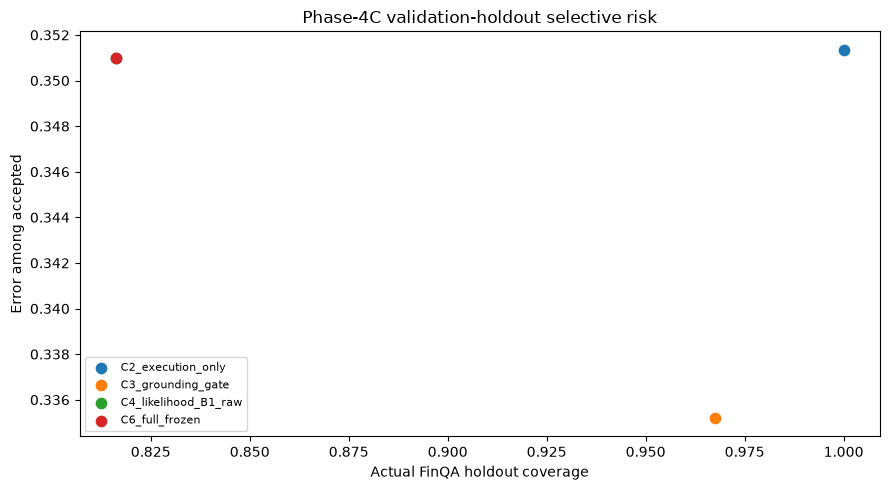

Phase-4C: PASS_METHODOLOGY_FROZEN Package: /home/heet18/Downloads/Research Papers/notebooks/artifacts/phase4c_full/Phase4C_Review_Package.zip
IMPORTANT: Fit-OOF selection chose likelihood-only; C6 is NOT evidence of a novel verifier-aware improvement.


In [11]:
fig,ax=plt.subplots(figsize=(9,5))
s=C6.sort_values('coverage')
for name,row in s.groupby('method'):
    if name in ['C6_full_frozen','C2_execution_only','C3_grounding_gate'] or 'C4_likelihood_B1_raw' in name:
        ax.scatter(row.coverage,row.selective_risk,label=name,s=55)
ax.set(xlabel='Actual FinQA holdout coverage',ylabel='Error among accepted',
       title='Phase-4C validation-holdout selective risk')
ax.legend(fontsize=8);fig.tight_layout();fig.savefig(OUT/'plots/C3_C6_selective_risk.png',dpi=180);plt.show()
missing=[x for x in ['C1_C2_answer_reconciliation.csv','C3_C6_ablation_holdout.csv',
        'C7_component_ablation.csv','C8_paired_significance.csv','C8_coverage_matched_comparison.csv',
        'C8_fiqa_selective_mae.csv','C9_efficiency.csv'] if not (OUT/'tables'/x).exists()]
GATES={'phase4b_full_frozen':True,'e5_baseline_1000':len(E5)==1000,
       'finqa_holdout_185':len(Hold)==185,'fiqa_holdout_25':len(qH)==25,
       'no_holdout_retraining':True,'no_threshold_refitting':True,
       'all_C1_to_C10_tables_written':not missing}
state='PASS_METHODOLOGY_FROZEN' if all(GATES.values()) else 'FAIL'
readiness={'phase':'Phase-4C','status':state,'gates':GATES,
    'winner_risk_policy':win,'fixed_coverage':goal,'n_finqa_holdout':185,'n_fiqa_holdout':25,
    'protected_test_sets_used':False,'fintrust_final_protocol':'NOT_VERIFIED',
    'no_claim_of_superiority_without_effect_estimate':True,
    'verifier_aware_policy_selected':win in ['B3_verifier','B4_grounding'],
    'novelty_status':('NOT_SUPPORTED_BY_FIT_ONLY_SELECTION' if win in ['B1_raw','B2_likelihood'] else 'REQUIRES_TEST_CONFIRMATION'),
    'cautions':['This is validation-holdout evidence, not a protected test result.',
        'Phase-4B already reported holdout; no new independent holdout exists.',
        'Full TrustFin-SLM may not beat execution-only or likelihood baseline.',
        'Grounding is numerical presence, not complete semantic grounding.']}
save('phase4c_readiness.json',readiness)
frozen={'phase':'Phase-4C','status':state,'base_model':'Qwen/Qwen3-1.7B',
    'frozen_sft_experiment':'E5','risk_policy':win,
    'selected_on':'Phase-4B calibration-fit OOF only',
    'threshold':fitmeta['thresholds_from_fit_oof'][win],
    'target_coverage':goal,'deterministic_gate':['official_executable_feature','program_structural_valid'],
    'FiQA_policy_file':'Phase-4B B6_fiqa_policy.json',
    'protect_test':'Do not access protected FinQA/FiQA/FOMC/FinTrust tests until methodology freeze is reviewed.',
    'limitation':'Any claim of TrustFin-SLM superiority must come from observed, verified test estimates.'}
save('phase4_methodology_freeze.json',frozen)
pkg=OUT/'Phase4C_Review_Package.zip'
with zipfile.ZipFile(pkg,'w',zipfile.ZIP_DEFLATED) as z:
    for file in sorted(OUT.rglob('*')):
        if file.is_file() and file!=pkg:z.write(file,file.relative_to(OUT))
print('Phase-4C:',state,'Package:',pkg)
if win not in ['B3_verifier','B4_grounding']:
    print('IMPORTANT: Fit-OOF selection chose likelihood-only; C6 is NOT evidence of a novel verifier-aware improvement.')
assert not missing, missing

## Output checklist for manuscript review

Share the executed notebook and `artifacts/phase4c_full/Phase4C_Review_Package.zip` (includes `phase4_methodology_freeze.json` and `phase4c_readiness.json`). Essential tables are `C1_C2_answer_reconciliation.csv`, `C3_C6_ablation_holdout.csv`, `C7_component_ablation.csv`, `C8_paired_significance.csv`, `C8_coverage_matched_comparison.csv`, `C8_fiqa_selective_mae.csv`, and `C9_efficiency.csv`.

**Next phase:** Review whether verifier-aware selective risk truly improves over execution-only and likelihood-only. Preserve the already frozen E5, risk features, thresholds and prompts. Resolve FinTrust dimension-specific scoring and then perform a **single protected-test evaluation** without altering the methodology.